# Plots a 9 panel hovmoller
Each ensemble member within the set of a user specified selection.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from netCDF4 import Dataset, num2date, date2num
from datetime import datetime
from matplotlib.dates import DateFormatter
import pandas as pd 
from matplotlib.lines import Line2D

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import matplotlib.ticker as mticker 
import os
import glob
import matplotlib.gridspec as gridspec

from metpy.units import units

import wrf
import metpy.calc as mpcalc
from wrf import (to_np, interplevel, geo_bounds, getvar, smooth2d, get_cartopy, cartopy_xlim,
                 cartopy_ylim, latlon_coords, destagger)

In [3]:
variation = ['fluxon', 'rst_on24', 'rst_on36', 'rst_on48', '', 'fluxoff', '', '', '']
init_times = ['0300','0303','0306',
             '0309','0312','0315',
             '0318','0321','0400']

In [28]:
set_name = variation[2]
title = '36 hours decoupled'

In [29]:
plotsdir = '/glade/u/home/athornton/qtrack/'

In [30]:
wrf_out_data = xr.open_dataset("/glade/campaign/univ/uncs0067/flux_experiments/cent_atl_case/init0300z/fluxon/wrfout_d01_2020-09-03_00:00:00")

lats, lons = latlon_coords(wrf_out_data['P'])
lats_np = to_np(lats)
lons_np = to_np(lons)
lats_np = lats_np[0,:,0]
lons_np = lons_np[0,0,:]

In [31]:
#cmap = 'RdYlBu_r'
cmap = 'RdBu_r'
def get_panel_plot(save_name, vorticity, current_ax, iplot):    
    # Get the longitude range from the Hovmöller plot data 
    lon_min = np.min(lons_np)
    lon_max = np.max(lons_np)
    
    # Bottom plot for Hovmöller diagram
    #ax= fig.add_subplot(gs[col,row])
    
    # Plot of chosen variable averaged over latitude 
    #clevs = np.arange(-0.00015, 0.00015, 0.000005)
    clevs = np.arange(-0.00010, 0.00010, 0.00001)
    cf = current_ax.contourf(lons_np, plot_times, vorticity, cmap=cmap, levels=clevs, extend='both')
    
    date_form = DateFormatter('%m-%d')
    current_ax.tick_params(axis="both", which="major", labelsize=16)

    current_ax.yaxis.set_major_formatter(date_form)
    current_ax.scatter(paulette_lons, times_list, label='Paulette')
    current_ax.scatter(rene_lons, times_list, marker='^', label='Rene')
    
    # Set some titles for Hovmöller diagram
    #plt.suptitle('630 hPa relative vorticity and surface wind speed', fontsize=14, weight='bold', y=0.93)
    plt.title(init_time+"z",
              loc='left', fontsize=16)
    
    #plt.savefig(plotsdir+'winds_vort600_hov_fluxON_'+str(start_date)+'.png')
    #return sm

    

In [32]:
rows = [0,1,2]
cols = [0,1,2]
f1 = init_times[:3],init_times[3:6],init_times[6:9]
f2 = np.array(f1)

In [33]:
f1 = init_times[:3],init_times[3:6],init_times[6:9]

In [34]:
f2 = np.array(f1)

0300
0309
0318
0303
0312
0321
0306
0315
0400


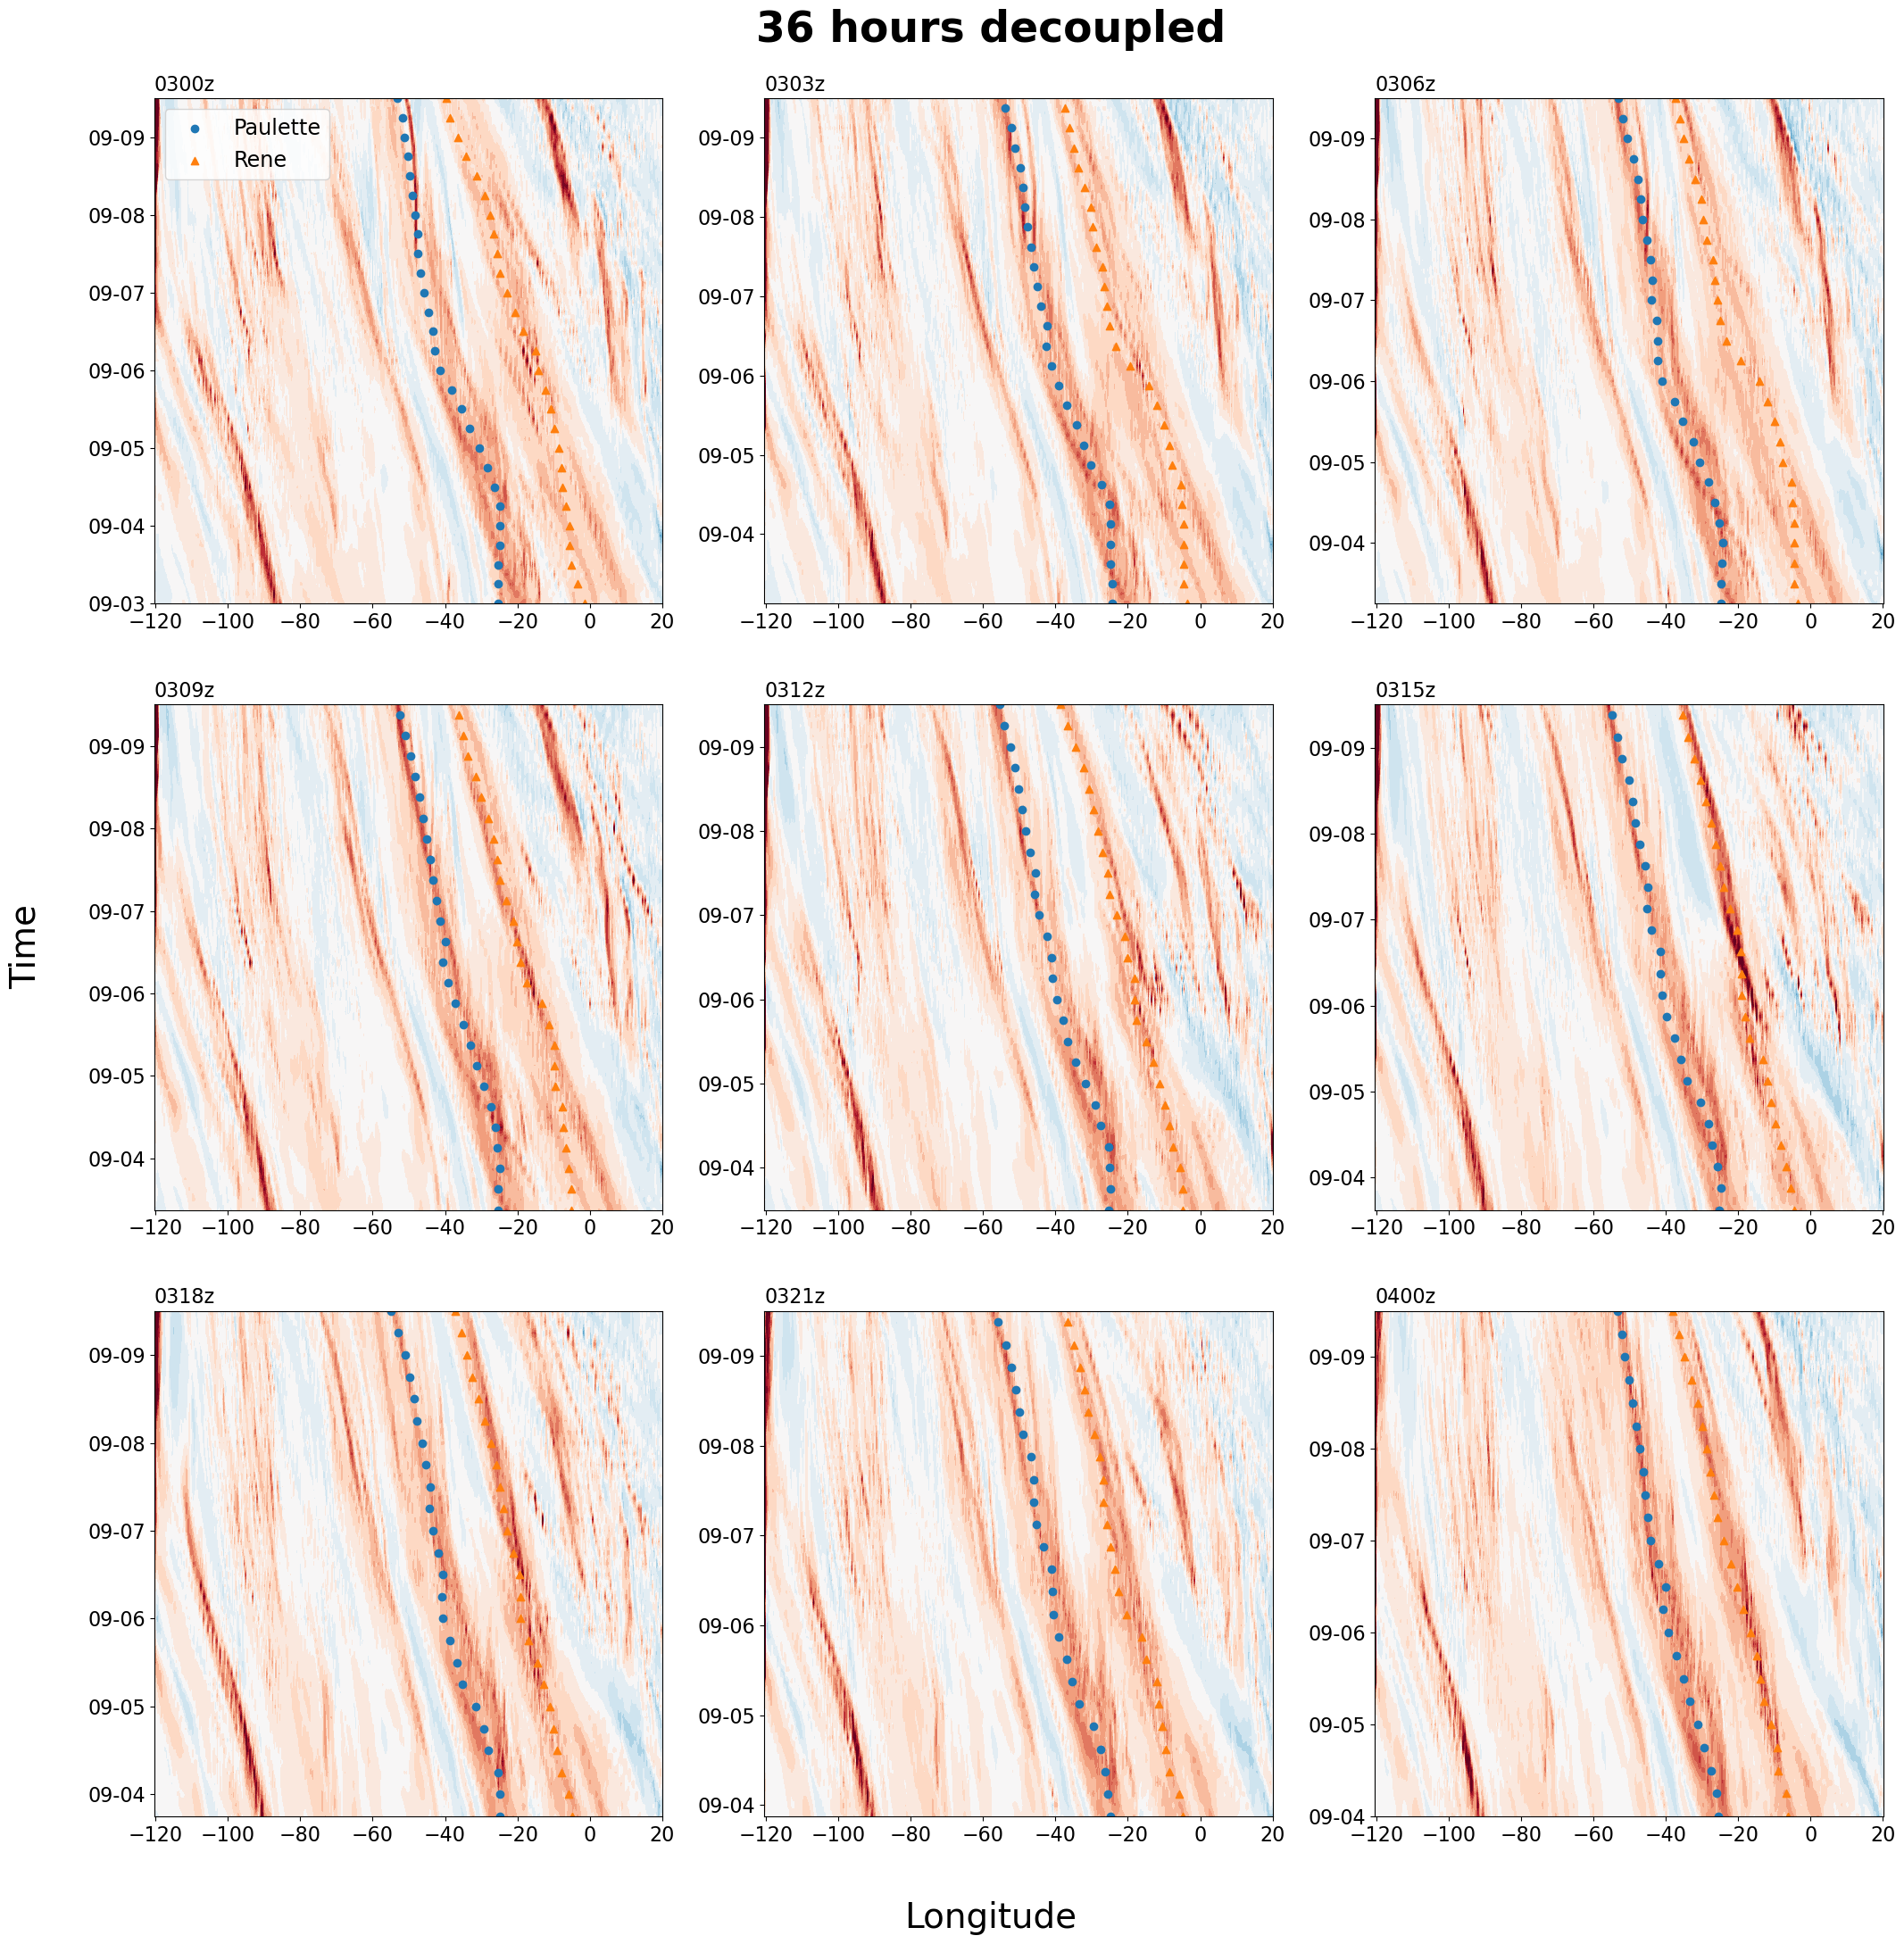

In [35]:
fig = plt.figure(figsize=(25,25))#3,3, subplot_kw={"projection": ccrs.PlateCarree()}, figsize=(20,10))
#cmap = 'BrBG'
plt.rcParams['savefig.dpi'] = 255
gs = gridspec.GridSpec(nrows=3, ncols=3)# height_ratios=[1, 10], hspace=0.08)

minlon = -80.
maxlon = 10.
minlat = 12.5
maxlat = 20.

# Plotting: 3 rows (lags) x 3 columns (tracks)
#for init_time in init_times:
for row  in rows:  # Each row corresponds to a lag
    for col in cols:  # Each column corresponds to a track
        # Get data
        init_time = f2[col, row]
        print(init_time)
        save_name = set_name +"_"+ init_time
        paulette = xr.open_dataset('/glade/u/home/athornton/qtrack/second_wave/second_wave_track_'+save_name+'.nc')
        rene     = xr.open_dataset('/glade/u/home/athornton/qtrack/main_wave/main_wave_track_'+save_name+'.nc')
        start_time ='2020-09-'+init_time[:2]+' '+init_time[2:]+':00'
        times_list = pd.date_range(start=start_time, end='2020-09-09 12:00', freq='6h')
        paulette_lons = paulette.lon[-len(times_list):]
        paulette_lats = paulette.lat[-len(times_list):]
        rene_lons = rene.lon[-len(times_list):]
        rene_lats = rene.lat[-len(times_list):]
        plot_times = pd.date_range(start=start_time, end='2020-09-09 12:00', freq='3h')

        vort = xr.open_dataset('/glade/u/home/athornton/qtrack/vort_files/vort_hov_'+set_name+'_'+init_time+'.nc')
        vorticity = vort.vort.values
        
        # Plot on the correct axis
        current_ax = fig.add_subplot(gs[col,row])

        sm = get_panel_plot(save_name, vorticity, current_ax, row * 3 + col)
        if init_time == '0300':
            current_ax.legend(fontsize='xx-large', loc='upper left')

plt.suptitle(title, fontsize=34, weight='bold', y=0.92)

fig.text(0.5, 0.06, 'Longitude', ha='center', fontsize=28)
fig.text(0.06, 0.5, 'Time', va='center', rotation='vertical', fontsize=28)
plt.savefig(plotsdir+'vort600_hov_'+set_name+'.png')

